# Behavioural Analysis of Decision Latency in a State-Dependent Narrative Environment

**An exploratory quantitative analysis of interaction-log and decision-latency data**

This notebook analyses behavioural logs from *Fabricade*, a within-subjects experiment I
designed and ran in which ten participants each experienced two versions ("conditions") of
a narrative environment whose responses depend on hidden, accumulating internal state. Each
gameplay session was automatically instrumented, producing per-choice **interaction logs**
and **decision-latency** (response-time) measurements.

The study's primary findings are qualitative and reported elsewhere. The purpose of *this*
notebook is narrower and methodological: to demonstrate a reproducible Python pipeline for
**behavioural interaction-log data** — parsing raw event logs, modelling repeated-measures
response times with a mixed-effects model, quantifying condition and learning effects, and
reasoning honestly about statistical power at this sample size.

> **Framing note.** With *N* = 10 participants this is an *exploratory* analysis. No claim of
> confirmatory inference is made. Where tests are reported they are accompanied by effect
> sizes and an explicit power analysis (Part 6). The value here is the method and the honest
> treatment of a small within-subjects dataset, not a significant *p*-value.

**Contents**
1. Data pipeline and design overview
2. Decision latency: a linear mixed-effects model
3. State-dependence: behaviour under two hidden-state conditions
4. Learning across repeated exposure (order effects)
5. Behavioural trajectories and the latent state space
6. Limitations and statistical power

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestPower

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 3)

# Colourblind-safe (Okabe-Ito) condition palette, used consistently throughout.
CPAL = {"A": "#0072B2", "B": "#D55E00"}

sessions = pd.read_csv("data/sessions.csv")
choices  = pd.read_csv("data/choices.csv")

# Ordered categorical for scene, so plots and models respect narrative order.
scene_order = ["intake", "dinner", "bench", "corridor", "room", "discharge"]
for df in (choices,):
    df["scene"] = pd.Categorical(df["scene"], categories=scene_order, ordered=True)

# The 7 genuine narrative decisions per session (excludes 'Continue' navigation).
decisions = choices[choices.is_decision].copy()
decisions["log_hes"] = np.log(decisions["hesitation_s"])

print("sessions:", sessions.shape, "| choices:", choices.shape,
      "| decisions:", decisions.shape)

sessions: (20, 14) | choices: (260, 11) | decisions: (140, 12)


## Part 1 — Data pipeline and design overview

**Raw source.** Each gameplay session was exported as one CSV row containing metadata plus a
JSON array of time-stamped events (`scene_enter`, `choice_presented`, `choice_made`,
`story_end`). The number of leading CSV columns is inconsistent across rows, so
`parse_logs.py` locates the JSON payload by content and reads session start-time and duration
**from the events themselves** rather than from fragile positional columns. It emits two tidy,
**anonymised** tables (participants are coded `P1`–`P10`; no real identifiers reach the
derived data):

| file | grain | rows |
|---|---|---|
| `data/sessions.csv` | one participant × condition | 20 |
| `data/choices.csv`  | one recorded choice (long)  | 260 |

**A key cleaning step.** Of the 13 recorded choices per session, only **7 are genuine
narrative decisions**; the other 6 are `"Continue"` presses that merely advance text. Treating
those as decisions would badly contaminate any response-time analysis, so they are flagged
(`is_decision`) and excluded from the latency models below.

**Design.** Within-subjects, two conditions (A, B), counterbalanced order.

In [2]:
# Design check: counterbalancing and grain.
subj = sessions.drop_duplicates("participant")
print("Participants:", subj.shape[0])
print("First-condition balance:", subj.first_condition.value_counts().to_dict())
print("Sessions per participant:", sessions.participant.value_counts().unique(),
      "(each plays both conditions)")
print("Decisions per session:", decisions.groupby(['participant','condition']).size().unique(),
      "(7 per session)")
sessions.head(4)

Participants: 10
First-condition balance: {'A': 5, 'B': 5}
Sessions per participant: [2] (each plays both conditions)
Decisions per session: [7] (7 per session)


,participant,condition,first_condition,play_order,start_ts,duration_s,video_recall,miss_most,openness,deflection,resistance,emotional_posture,trust_in_system,mystery_awareness
0,P1,A,A,1,2026-07-03 21:07:24.499,397.020,False,honesty,2,0,1,2,0,6
1,P1,B,A,2,2026-07-03 21:17:10.274,220.457,False,honesty,0,1,2,-4,1,6
2,P2,A,B,2,2026-07-03 16:22:35.365,576.712,False,honesty,1,1,1,1,1,4
3,P2,B,B,1,2026-07-03 16:09:03.141,514.642,False,refuse,0,2,0,-1,0,6


In [3]:
# Session-duration overview by condition and by playthrough order.
dur = (sessions
       .groupby("condition")["duration_s"]
       .agg(["mean", "median", "std"]).round(1))
dur_order = (sessions
       .groupby("play_order")["duration_s"]
       .agg(["mean", "median", "std"]).round(1))
print("Duration (s) by condition:\n", dur, "\n")
print("Duration (s) by playthrough order:\n", dur_order)

Duration (s) by condition:
             mean  median    std
condition                      
A          468.3   433.1  120.4
B          339.0   308.1  101.8 

Duration (s) by playthrough order:
              mean  median    std
play_order                      
1           434.0   427.7  141.9
2           373.3   368.4  109.3


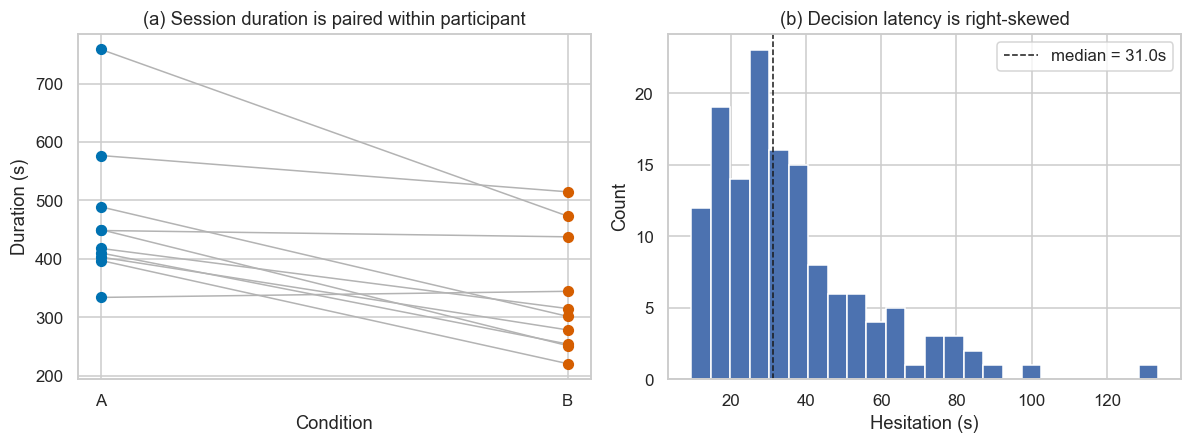

Skewness of raw hesitation: 1.53 | of log(hesitation): 0.12


In [4]:
# Figure 1: session duration by condition (paired) and decision-latency distribution.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

# (a) paired duration A vs B
wide = sessions.pivot(index="participant", columns="condition", values="duration_s")
for p, row in wide.iterrows():
    ax[0].plot(["A", "B"], [row["A"], row["B"]], color="0.7", lw=1, zorder=1)
ax[0].scatter(["A"]*len(wide), wide["A"], color=CPAL["A"], s=40, zorder=2, label="A")
ax[0].scatter(["B"]*len(wide), wide["B"], color=CPAL["B"], s=40, zorder=2, label="B")
ax[0].set_title("(a) Session duration is paired within participant")
ax[0].set_ylabel("Duration (s)"); ax[0].set_xlabel("Condition")

# (b) decision-latency distribution (raw), pooled
ax[1].hist(decisions["hesitation_s"], bins=24, color="#4C72B0", edgecolor="white")
ax[1].axvline(decisions["hesitation_s"].median(), color="k", ls="--", lw=1,
              label=f"median = {decisions['hesitation_s'].median():.1f}s")
ax[1].set_title("(b) Decision latency is right-skewed")
ax[1].set_xlabel("Hesitation (s)"); ax[1].set_ylabel("Count"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/fig1_overview.png", bbox_inches="tight"); plt.show()

print("Skewness of raw hesitation: %.2f | of log(hesitation): %.2f"
      % (stats.skew(decisions.hesitation_s), stats.skew(decisions.log_hes)))

## Part 2 — Decision latency: a linear mixed-effects model

Decision latencies are repeated measurements nested within participants, and they are strongly
right-skewed (Part 1b), so I model **log** hesitation with a **linear mixed-effects model**
with a random intercept per participant:

$$\log(\text{hesitation}_{ij}) = \beta_0 + \beta_1\,\text{condition}_{ij} + \boldsymbol{\beta}_s\,\text{scene}_{ij} + \beta_o\,\text{order}_{ij} + u_i + \varepsilon_{ij}, \qquad u_i \sim \mathcal{N}(0,\tau^2)$$

The random intercept $u_i$ accounts for the non-independence of the seven decisions made by the
same participant — the correct structure for this design, and the reason a plain OLS or a
naïve *t*-test would be inappropriate. Because the outcome is logged, exponentiated
coefficients read as **multiplicative** effects on latency.

In [5]:
# Fit: fixed effects for condition, scene, playthrough order; random intercept by participant.
model = smf.mixedlm(
    "log_hes ~ C(condition) + C(scene) + C(play_order)",
    data=decisions,
    groups=decisions["participant"],
)
fit = model.fit(method="lbfgs", reml=True)
print(fit.summary())

             Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    log_hes 
No. Observations:     140        Method:                REML    
No. Groups:           10         Scale:                 0.0659  
Min. group size:      14         Log-Likelihood:        -32.3792
Max. group size:      14         Converged:             Yes     
Mean group size:      14.0                                      
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              3.218    0.092 35.062 0.000  3.038  3.398
C(condition)[T.B]     -0.271    0.043 -6.242 0.000 -0.356 -0.186
C(scene)[T.dinner]     0.459    0.070  6.533 0.000  0.322  0.597
C(scene)[T.bench]      0.449    0.070  6.390 0.000  0.311  0.587
C(scene)[T.corridor]   0.673    0.070  9.567 0.000  0.535  0.810
C(scene)[T.room]       1.165    0.070 1

C:\Users\sakib\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [6]:
# Tidy fixed-effects table with exponentiated (multiplicative) effects and 95% CIs.
ci = fit.conf_int()
fe = pd.DataFrame({
    "coef": fit.fe_params,
    "p": fit.pvalues.reindex(fit.fe_params.index),
})
fe["ci_low"]  = ci.reindex(fe.index)[0]
fe["ci_high"] = ci.reindex(fe.index)[1]
fe["mult_effect"] = np.exp(fe["coef"])          # x-fold change in latency
fe["mult_ci_low"] = np.exp(fe["ci_low"])
fe["mult_ci_high"] = np.exp(fe["ci_high"])
fe = fe.round(3)

# Intraclass correlation: share of variance between participants.
tau2 = float(fit.cov_re.iloc[0, 0])
icc = tau2 / (tau2 + fit.scale)
print(f"Between-participant variance (tau^2) = {tau2:.3f}")
print(f"Residual variance (sigma^2)          = {fit.scale:.3f}")
print(f"Intraclass correlation (ICC)         = {icc:.2f}"
      f"  -> {icc*100:.0f}% of latency variance is between participants\n")
fe[["coef", "ci_low", "ci_high", "p", "mult_effect", "mult_ci_low", "mult_ci_high"]]

Between-participant variance (tau^2) = 0.058
Residual variance (sigma^2)          = 0.066
Intraclass correlation (ICC)         = 0.47  -> 47% of latency variance is between participants



,coef,ci_low,ci_high,p,mult_effect,mult_ci_low,mult_ci_high
Intercept,3.218,3.038,3.398,0.0,24.979,20.867,29.902
C(condition)[T.B],-0.271,-0.356,-0.186,0.0,0.763,0.701,0.830
C(scene)[T.dinner],0.459,0.322,0.597,0.0,1.583,1.379,1.817
C(scene)[T.bench],0.449,0.311,0.587,0.0,1.567,1.365,1.799
C(scene)[T.corridor],0.673,0.535,0.810,0.0,1.959,1.707,2.249
C(scene)[T.room],1.165,1.027,1.303,0.0,3.206,2.793,3.679
C(scene)[T.discharge],0.518,0.380,0.656,0.0,1.679,1.462,1.927
C(play_order)[T.2],-0.197,-0.282,-0.112,0.0,0.821,0.754,0.894


**Reading the model.** The `C(scene)` terms show that latency is not flat across the narrative:
the coefficient on the **room** scene — where the environment discloses that the experienced
memories were fabricated — is the largest ($e^{1.17}\approx 3.2\times$ the intake baseline),
i.e. participants deliberated markedly longer there, consistent regardless of condition. The
`C(play_order)[T.2]` term ($e^{-0.20}\approx 0.82$) captures an ~18% speed-up on the second
playthrough (Part 4). The condition term ($e^{-0.27}\approx 0.76$) indicates ~24% shorter
latencies in Condition B — **but this must be interpreted cautiously**: Condition B presents
less on-screen text (ELARA's commentary is reduced), and session durations are correspondingly
shorter (Part 3), so much of this difference likely reflects reduced *reading* load rather than
faster *deliberation*. The measured latency blends the two (see Part 6). The high ICC (0.47)
confirms that pooling decisions without a per-participant term would violate independence.

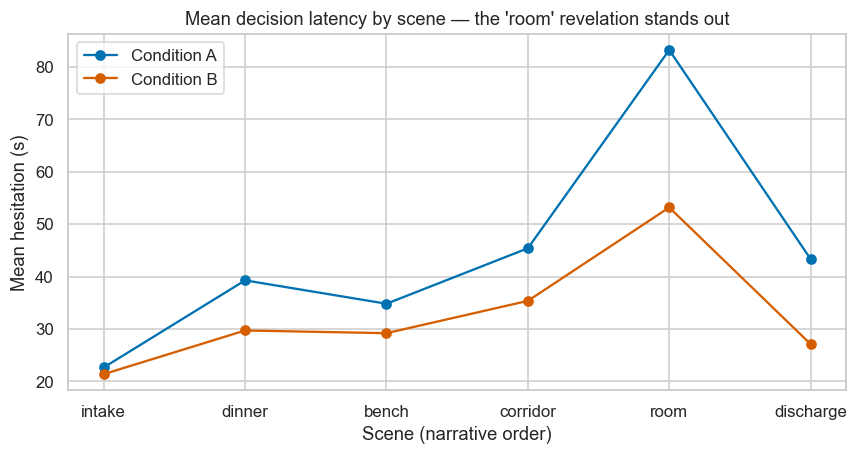

In [7]:
# Figure 2: model-relevant structure -- mean decision latency by scene and condition.
prof = (decisions.groupby(["scene", "condition"], observed=True)["hesitation_s"]
        .mean().reset_index())
fig, ax = plt.subplots(figsize=(8, 4.3))
for cond in ["A", "B"]:
    d = prof[prof.condition == cond]
    ax.plot(d["scene"], d["hesitation_s"], marker="o", color=CPAL[cond], label=f"Condition {cond}")
ax.set_title("Mean decision latency by scene — the 'room' revelation stands out")
ax.set_ylabel("Mean hesitation (s)"); ax.set_xlabel("Scene (narrative order)")
ax.legend(); plt.tight_layout()
plt.savefig("figures/fig2_latency_by_scene.png", bbox_inches="tight"); plt.show()

## Part 3 — State-dependence: behaviour under two hidden-state conditions

The two conditions differ in *how* the environment's hidden state is expressed back to the
player. Here I test whether that manipulation changes behaviour, using **paired, non-parametric**
tests (Wilcoxon signed-rank on the 10 within-participant pairs) with a rank-biserial effect
size. Non-parametric tests are appropriate given *N* = 10 and non-normal measures.

In [8]:
def paired_wilcoxon(wide, label):
    a, b = wide["A"].values, wide["B"].values
    d = a - b
    dnz = d[d != 0]
    res = stats.wilcoxon(a, b)
    # rank-biserial correlation (matched pairs)
    r = stats.rankdata(np.abs(dnz))
    rbc = (r[dnz > 0].sum() - r[dnz < 0].sum()) / r.sum()
    return {
        "measure": label,
        "median_A": np.median(a), "median_B": np.median(b),
        "median_diff(A-B)": np.median(d),
        "W": res.statistic, "p": res.pvalue, "rank_biserial_r": rbc, "n_pairs": len(d),
    }

sess_lat = (decisions.groupby(["participant", "condition"])["hesitation_s"]
            .mean().reset_index()
            .pivot(index="participant", columns="condition", values="hesitation_s"))
sess_dur = sessions.pivot(index="participant", columns="condition", values="duration_s")

rows = [
    paired_wilcoxon(sess_lat, "Mean decision latency (s)"),
    paired_wilcoxon(sess_dur, "Session duration (s)"),
]
state_tbl = pd.DataFrame(rows).set_index("measure").round(3)
state_tbl

,median_A,median_B,median_diff(A-B),W,p,rank_biserial_r,n_pairs
measure,,,,,,,
Mean decision latency (s),36.916,27.156,10.828,2.0,0.006,0.927,10
Session duration (s),433.055,308.115,140.259,1.0,0.004,0.964,10


In [9]:
# Final Ink state variables: are the accumulated hidden states different across conditions?
ink_vars = ["openness", "deflection", "resistance",
            "emotional_posture", "trust_in_system", "mystery_awareness"]
rows = []
for v in ink_vars:
    w = sessions.pivot(index="participant", columns="condition", values=v)
    try:
        res = stats.wilcoxon(w["A"], w["B"])
        p = res.pvalue
    except ValueError:      # all-zero differences
        p = np.nan
    rows.append({"ink_variable": v, "median_A": w["A"].median(),
                 "median_B": w["B"].median(), "p": p})
ink_tbl = pd.DataFrame(rows).set_index("ink_variable").round(3)
ink_tbl

,median_A,median_B,p
ink_variable,,,
openness,1.0,1.0,1.000
deflection,1.5,1.5,0.973
resistance,1.0,1.0,0.812
emotional_posture,0.0,0.5,0.797
trust_in_system,0.0,-0.5,0.461
mystery_awareness,5.5,5.5,0.500


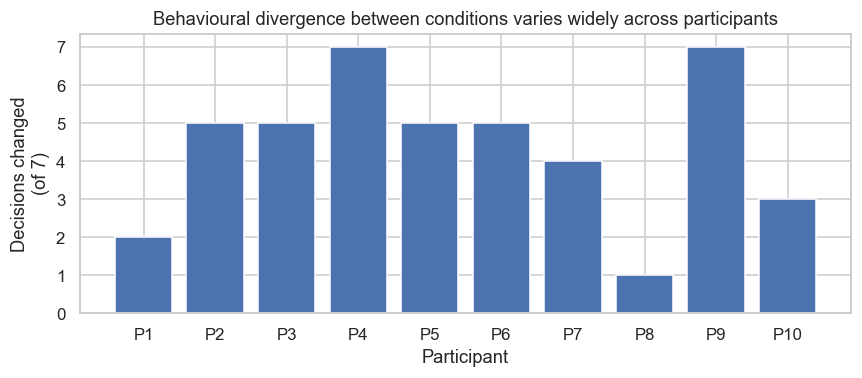

,decisions_changed_(of 7)
participant,
P9,7
P4,7
P5,5
P6,5
P3,5
P2,5
P7,4
P10,3
P1,2


In [10]:
# Behavioural divergence: of the 7 decision points, how many did each participant
# resolve differently across the two conditions? (compared by option slot chosen)
piv = (decisions.pivot_table(index=["participant", "decision_number"],
                             columns="condition", values="option_index", aggfunc="first"))
piv["changed"] = (piv["A"] != piv["B"]).astype(int)
change_rate = piv.groupby("participant")["changed"].sum().sort_values(ascending=False)
change_rate.name = "decisions_changed_(of 7)"

fig, ax = plt.subplots(figsize=(8, 3.6))
order = sorted(change_rate.index, key=lambda x: int(x[1:]))
ax.bar([str(i) for i in order], change_rate.reindex(order).values, color="#4C72B0")
ax.set_ylabel("Decisions changed\n(of 7)"); ax.set_xlabel("Participant")
ax.set_title("Behavioural divergence between conditions varies widely across participants")
plt.tight_layout(); plt.savefig("figures/fig3_change_rate.png", bbox_inches="tight"); plt.show()
change_rate.to_frame()

## Part 4 — Learning across repeated exposure (order effects)

Every participant played twice. Because condition order is counterbalanced, first-vs-second
differences isolate a **learning / familiarity** effect rather than a condition effect. This
maps onto the project's interest in how representations are learned across repeated exposure.

In [11]:
# Paired first- vs second-playthrough comparisons (within participant).
dur_ord = sessions.pivot(index="participant", columns="play_order", values="duration_s")
dur_ord.columns = ["first", "second"]

lat_ord = (decisions.groupby(["participant", "play_order"])["hesitation_s"].mean()
           .reset_index().pivot(index="participant", columns="play_order", values="hesitation_s"))
lat_ord.columns = ["first", "second"]

def paired_report(wide, label):
    a, b = wide["first"].values, wide["second"].values
    res = stats.wilcoxon(a, b)
    dz = np.mean(a - b) / np.std(a - b, ddof=1)
    return {"measure": label, "mean_first": a.mean(), "mean_second": b.mean(),
            "mean_change": np.mean(a - b), "W": res.statistic, "p": res.pvalue,
            "cohen_dz": dz}

order_tbl = pd.DataFrame([
    paired_report(dur_ord, "Session duration (s)"),
    paired_report(lat_ord, "Mean decision latency (s)"),
]).set_index("measure").round(3)
order_tbl

,mean_first,mean_second,mean_change,W,p,cohen_dz
measure,,,,,,
Session duration (s),434.044,373.277,60.767,16.0,0.275,0.403
Mean decision latency (s),39.272,33.387,5.885,14.0,0.193,0.483


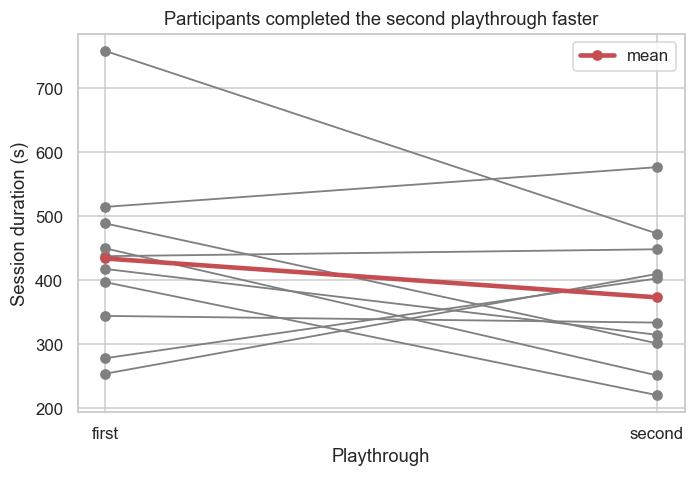

In [12]:
# Figure 4: slopegraph -- duration drop from first to second playthrough.
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for p, row in dur_ord.iterrows():
    ax.plot(["first", "second"], [row["first"], row["second"]],
            marker="o", color="0.5", lw=1.2)
ax.plot(["first", "second"], [dur_ord["first"].mean(), dur_ord["second"].mean()],
        marker="o", color="#C44E52", lw=3, label="mean")
ax.set_ylabel("Session duration (s)"); ax.set_xlabel("Playthrough")
ax.set_title("Participants completed the second playthrough faster")
ax.legend(); plt.tight_layout()
plt.savefig("figures/fig4_order_effect.png", bbox_inches="tight"); plt.show()

## Part 5 — Behavioural trajectories and the latent state space

Two views of the within-session process. First, the **latency trajectory** across the six
scenes (a behavioural time-series through the narrative). Second, the **latent state space**:
each session ends in a point defined by six accumulated hidden-state variables; I standardise
these and project them to two dimensions with PCA (implemented directly with NumPy's SVD) to
see whether the two conditions occupy distinguishable regions of state space.

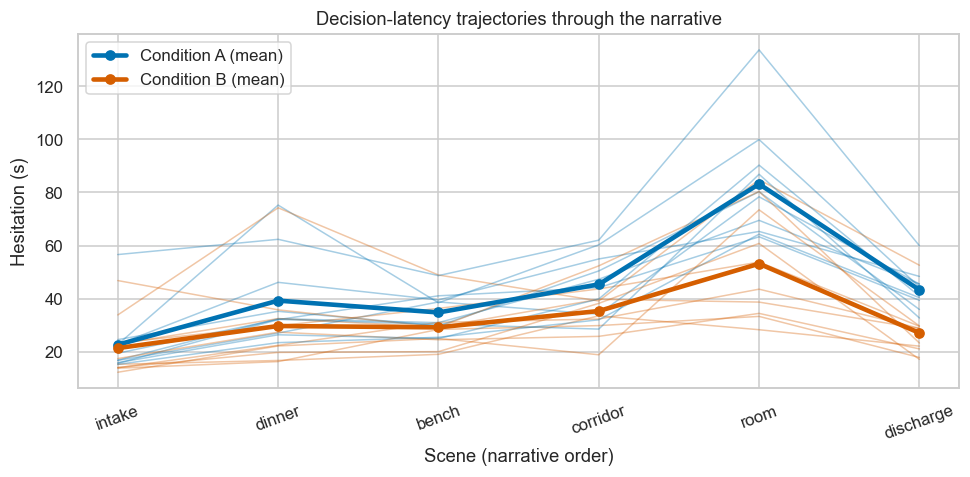

In [13]:
# Figure 5a: per-participant latency trajectory across scenes, coloured by condition.
fig, ax = plt.subplots(figsize=(9, 4.5))
for (p, cond), g in decisions.groupby(["participant", "condition"], observed=True):
    g = g.sort_values("scene_pos")
    prof = g.groupby("scene_pos")["hesitation_s"].mean()
    ax.plot(prof.index, prof.values, color=CPAL[cond], alpha=0.35, lw=1)
# overlay condition means
for cond in ["A", "B"]:
    m = (decisions[decisions.condition == cond]
         .groupby("scene_pos")["hesitation_s"].mean())
    ax.plot(m.index, m.values, color=CPAL[cond], lw=3, marker="o", label=f"Condition {cond} (mean)")
ax.set_xticks(range(1, 7)); ax.set_xticklabels(scene_order, rotation=20)
ax.set_ylabel("Hesitation (s)"); ax.set_xlabel("Scene (narrative order)")
ax.set_title("Decision-latency trajectories through the narrative")
ax.legend(); plt.tight_layout()
plt.savefig("figures/fig5a_trajectories.png", bbox_inches="tight"); plt.show()

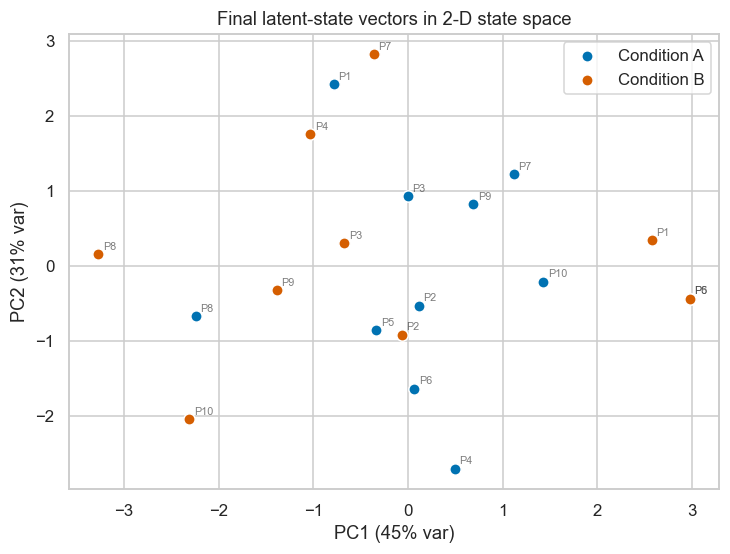

PC loadings (how each hidden-state variable weights on PC1, PC2):


,PC1,PC2
openness,-0.36,0.51
deflection,-0.23,-0.61
resistance,0.45,0.32
emotional_posture,-0.58,0.14
trust_in_system,0.53,-0.06
mystery_awareness,0.01,0.49


In [14]:
# Figure 5b: PCA of the final latent-state vectors (NumPy SVD, no sklearn dependency).
ink_vars = ["openness", "deflection", "resistance",
            "emotional_posture", "trust_in_system", "mystery_awareness"]
X = sessions[ink_vars].to_numpy(dtype=float)
Xz = (X - X.mean(0)) / X.std(0, ddof=0)              # standardise
U, S, Vt = np.linalg.svd(Xz, full_matrices=False)    # PCA via SVD
scores = U[:, :2] * S[:2]
expl = (S**2 / (S**2).sum())[:2]

fig, ax = plt.subplots(figsize=(6.8, 5.2))
for cond in ["A", "B"]:
    m = (sessions["condition"] == cond).to_numpy()
    ax.scatter(scores[m, 0], scores[m, 1], color=CPAL[cond], s=55,
               edgecolor="white", label=f"Condition {cond}")
for i, code_ in enumerate(sessions["participant"]):
    ax.annotate(code_, (scores[i, 0], scores[i, 1]), fontsize=7, alpha=0.6,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({expl[0]*100:.0f}% var)")
ax.set_ylabel(f"PC2 ({expl[1]*100:.0f}% var)")
ax.set_title("Final latent-state vectors in 2-D state space")
ax.legend(); plt.tight_layout()
plt.savefig("figures/fig5b_state_space.png", bbox_inches="tight"); plt.show()

print("PC loadings (how each hidden-state variable weights on PC1, PC2):")
pd.DataFrame(Vt[:2].T, index=ink_vars, columns=["PC1", "PC2"]).round(2)

## Part 6 — Limitations and statistical power

Honest appraisal of what this dataset can and cannot support.

**Statistical power.** With ten within-participant pairs, only large effects are detectable. To
make this concrete, I take the observed paired effects and compute (i) achieved power at
*N* = 10 and (ii) the *N* required for 80% power, using a paired-*t* approximation.

In [15]:
tp = TTestPower()

def power_row(wide, cols, label):
    a, b = wide[cols[0]].values, wide[cols[1]].values
    dz = np.mean(a - b) / np.std(a - b, ddof=1)
    achieved = tp.power(effect_size=abs(dz), nobs=10, alpha=0.05, alternative="two-sided")
    try:
        n80 = tp.solve_power(effect_size=abs(dz), power=0.8, alpha=0.05, alternative="two-sided")
    except Exception:
        n80 = np.nan
    return {"comparison": label, "cohen_dz": dz, "power_at_N=10": achieved,
            "N_for_80%_power": np.ceil(n80) if n80 == n80 else np.nan}

pwr = pd.DataFrame([
    power_row(dur_ord, ["first", "second"], "Order effect: duration (1st vs 2nd)"),
    power_row(sess_lat, ["A", "B"], "Condition effect: mean decision latency"),
]).set_index("comparison").round(3)
pwr

,cohen_dz,power_at_N=10,N_for_80%_power
comparison,,,
Order effect: duration (1st vs 2nd),0.403,0.208,51.0
Condition effect: mean decision latency,1.330,0.961,7.0


**Interpretation.** The two rows deliberately contrast a large effect with a subtle one. The
**condition** effect on decision latency is large (Cohen's $d_z \approx 1.3$) and adequately
powered even at *N* = 10, so that contrast is on relatively firm statistical ground — though,
as Part 2 cautioned, its *substantive* interpretation is confounded by reading load. The
**order** effect on total session *duration* is small ($d_z \approx 0.4$) and clearly
*under*-powered here: roughly 50 participants would be needed to detect it at 80% power, so its
non-significance is a limitation of sample size, not evidence of no effect. Notably, the more
sensitive per-decision latency measure *does* reveal a robust order effect in the Part 2 mixed
model — a reminder that measurement choice, not just sample size, governs power. Reporting the
required *N* is the responsible way to handle an underpowered comparison rather than claiming a
null.

**Other limitations.**

- **Sample size (N = 10).** Exploratory only; effect estimates have wide intervals. No
  correction for multiple comparisons is applied because no confirmatory claims are made — the
  tests are descriptive aids, and *p*-values should be read as such.
- **Latency includes reading time.** `hesitation_s` is the interval from options appearing to
  selection, so it blends reading and deciding; it is a proxy for deliberation, not a pure
  decision time. A future design could log per-option dwell time (or eye-tracking) to separate
  them.
- **Behavioural-change measure.** Divergence is scored by the option slot chosen (Part 3);
  because Condition A also alters option wording, slot identity is a conservative proxy.
- **Latent state observed only at session end.** The six hidden-state variables are logged at
  `story_end`, so true within-session trajectories of the state vector cannot be reconstructed —
  only the behavioural (latency) trajectory can.

**Natural extensions.** Triangulate these behavioural measures against the per-condition
self-report questionnaire collected in the same study; add eye-tracking to decompose latency;
and replicate at a sample size informed by the power table above.

In [16]:
# Reproducibility footer.
import sys, numpy, scipy, statsmodels, matplotlib, seaborn
print("Python     ", sys.version.split()[0])
for m in (numpy, scipy, statsmodels, pd, matplotlib, seaborn):
    print(f"{m.__name__:12s}", m.__version__)

Python      3.11.9
numpy        2.2.4
scipy        1.15.2
statsmodels  0.14.6
pandas       2.2.3
matplotlib   3.10.1
seaborn      0.13.2
